In [1]:
%pip install torch torchvision matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torchvision.datasets import MNIST
from torch.utils.data import DataLoader

from sklearn.metrics import classification_report, recall_score, accuracy_score

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
# CHECK PYTORCH AND ITS DEVICE

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

In [5]:
trainset = MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

testset = MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(trainset))
print("Testing images:", len(testset))

Training images: 60000
Testing images: 10000


In [6]:
# creating the datsloader 

trainloader = DataLoader(trainset, batch_size = 64 , shuffle = True)
testloader =  DataLoader(testset , batch_size = 64 , shuffle = True)


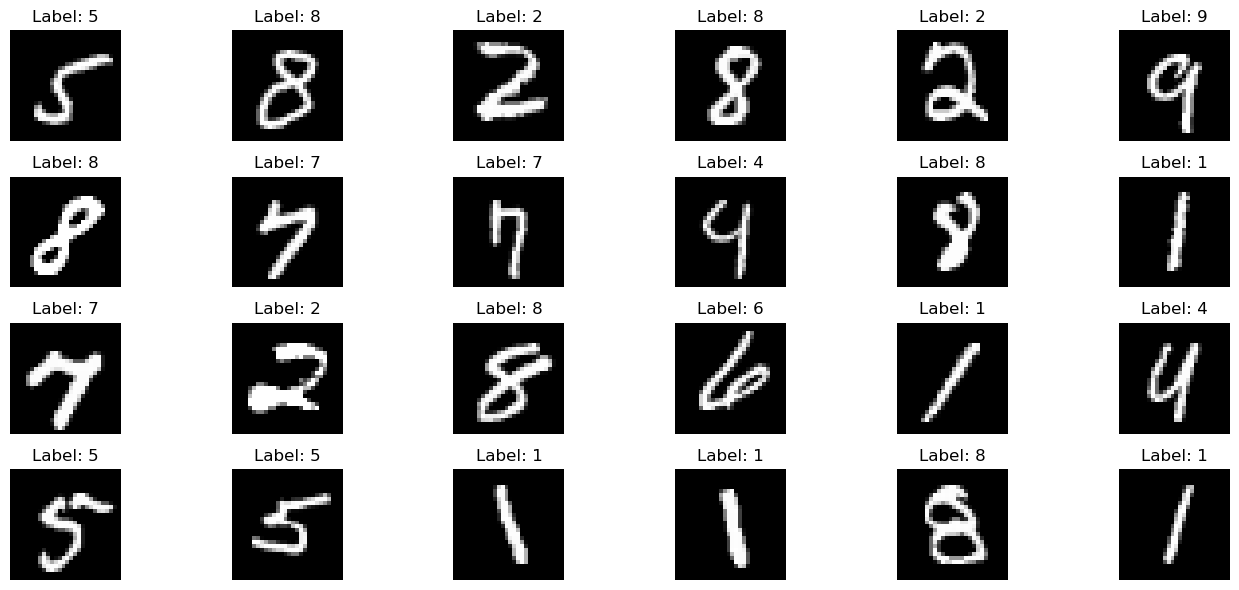

In [7]:
# This helps us verify that the dataset has loaded correctly.

'''
- trainloader: Loads MNIST data in batches.
- iter(trainloader): Creates an iterator to access batches one by one.
- next(): Fetches the first batch.
- images: Stores the handwritten digit images.
- labels: Stores the actual digit values (0–9).
For example, if your batch size is 64:
- images contains 64 images.
- labels contains 64 corresponding labels.
2. Create a plotting area


plt.subplots(2, 5): Creates a grid with 2 rows and 5 columns.



Total plots = 2 × 5 = 10.



figsize=(12, 5): Sets the overall figure size (width = 12, height = 5 inches).

Understand the two important things:
- axes.flat: Converts the 2D axes array into a 1D sequence.
- enumerate(): Gives you both the index (i) and the corresponding plotting area (ax)



- labels[i]: Gets the actual digit label.
- .item(): Converts a single PyTorch tensor value into a normal Python number.
- set_title(): Displays that number above the image.
For example, if the image contains digit 7, the title will be:


'''
images, labels = next(iter(trainloader))

fig, axes = plt.subplots(4, 6, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


# BUILDING & TRAINING & EVALUATING (CNN)

In [8]:
'''

CONVOLUTIONAL LAYERS: EXTRACT SPATIAL FEATURES

BATCH NORMALIZATION: STABLIZE AND ACCELRATE TRAINING

ReLU: INTODUCE NON-LINEARITY

MAX POOLING: REDUCE SPATIAL DIMENSIONS

DROPOUT: REDUCE OVERFITTING

FULLY CONNECTED LAYERS: PERFORM CLASSFICATION


'''


class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.conv_layers = nn.Sequential(

            # First convolution block
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),

            # Second convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),

            nn.Dropout2d(0.15)
        )

        self.fc_layers = nn.Sequential(

            nn.Linear(7 * 7 * 64, 128),
            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.conv_layers(x)

        x = x.view(x.size(0), -1)

        x = self.fc_layers(x)

        return x

In [9]:
# INITIASILZING THE CNN

cnn_model = CNN().to(device)

criterion = nn.CrossEntropyLoss()

cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

print(cnn_model)

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.15, inp

In [ ]:
epochs = 8

cnn_train_losses = []

for epoch in range(epochs):

    cnn_model.train()

    epoch_training_loss = 0.0

    for images, labels in trainloader:

        images = images.to(device)
        labels = labels.to(device)

        cnn_optimizer.zero_grad()

        outputs = cnn_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        cnn_optimizer.step()

        epoch_training_loss += loss.item()

    avg_loss = epoch_training_loss / len(trainloader)

    cnn_train_losses.append(avg_loss)

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Training Loss: {avg_loss:.4f}"
    )

print("CNN training completed!")

Epoch 1/8, Training Loss: 0.1361
Epoch 2/8, Training Loss: 0.0583
Epoch 3/8, Training Loss: 0.0467


In [ ]:
cnn_model.eval()

correct_labels = 0
total_labels = 0

cnn_predictions = []
cnn_actual = []

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_model(images)

        _, predicted = torch.max(outputs, 1)

        correct_labels += (predicted == labels).sum().item()

        total_labels += labels.size(0)

        cnn_predictions.extend(predicted.cpu().numpy())
        cnn_actual.extend(labels.cpu().numpy())

cnn_accuracy = correct_labels / total_labels * 100

print(f"CNN Accuracy = {cnn_accuracy:.2f}%")

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_cnn = confusion_matrix(cnn_actual, cnn_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=range(10)
)

disp.plot(cmap="Blues")

plt.title("CNN Confusion Matrix")
plt.show()


# BUILDING RNN MODEL USING LSTM

In [ ]:
# For the RNN, we'll treat each image as a sequence of 28 rows.
# Each time step contains 28 pixel values. => 
# Thus, each image becomes a sequence of length 28with input size 28.

'''
We'll use a Bidirectional LSTM with two layers.

Why?
- LSTM handles long-term dependencies better than a basic RNN.
- Bidirectional LSTM processes the sequence in forward and backward directions.
- Two layers allow the model to learn more complex patterns.

'''

# BUILDING  the lstm model  
class LSTMModel(nn.Module):

    def __init__(self, input_size=28, hidden_size=128, num_layers=2):
        super(LSTMModel, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.fc = nn.Sequential(

            nn.Linear(hidden_size * 2, 128),
            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, 10)
        )

    def forward(self, x):

        # Remove channel dimension
        x = x.squeeze(1)

        # LSTM forward pass
        out, (hidden, cell) = self.lstm(x)

        # Last layer's forward and backward hidden states
        forward_hidden = hidden[-2]

        backward_hidden = hidden[-1]

        # Concatenate both directions
        final_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        # Classification
        out = self.fc(final_hidden)

        return out

In [ ]:
lstm_model = LSTMModel().to(device)

criterion = nn.CrossEntropyLoss()

lstm_optimizer = optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print(lstm_model)

# TRAINING THE LSTM MODEL 

In [ ]:
epochs = 8

lstm_train_losses = []

for epoch in range(epochs):

    lstm_model.train()

    epoch_training_loss = 0.0

    for images, labels in trainloader:

        images = images.to(device)
        labels = labels.to(device)

        lstm_optimizer.zero_grad()

        outputs = lstm_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        lstm_optimizer.step()

        epoch_training_loss += loss.item()

    avg_loss = epoch_training_loss / len(trainloader)

    lstm_train_losses.append(avg_loss)

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Training Loss: {avg_loss:.4f}"
    )

print("LSTM training completed!")

In [ ]:
lstm_model.eval()

correct_labels = 0
total_labels = 0

lstm_predictions = []
lstm_actual = []

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = lstm_model(images)

        _, predicted = torch.max(outputs, 1)

        correct_labels += (predicted == labels).sum().item()

        total_labels += labels.size(0)

        lstm_predictions.extend(predicted.cpu().numpy())
        lstm_actual.extend(labels.cpu().numpy())

lstm_accuracy = correct_labels / total_labels * 100

print(f"LSTM Accuracy = {lstm_accuracy:.2f}%")

In [ ]:
cm_lstm = confusion_matrix(lstm_actual, lstm_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lstm,
    display_labels=range(10)
)

disp.plot(cmap="Greens")

plt.title("LSTM Confusion Matrix")
plt.show()

# NOW COMAPRE  CNN AND LSTM 

In [ ]:
print("CNN Accuracy:", round(cnn_accuracy, 2), "%")

print("LSTM Accuracy:", round(lstm_accuracy, 2), "%")

if cnn_accuracy > lstm_accuracy:

    print("CNN performs better!")

elif lstm_accuracy > cnn_accuracy:

    print("LSTM performs better!")

else:

    print("Both models have equal accuracy!")

# Cell 19 — Visualize accuracy comparison

In [ ]:
models = ["CNN", "LSTM"]

accuracies = [cnn_accuracy, lstm_accuracy]

plt.figure(figsize=(7, 5))

plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.xlabel("Models")

plt.title("CNN vs LSTM Accuracy Comparison")

plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.show()

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(cnn_train_losses, label="CNN")

plt.plot(lstm_train_losses, label="LSTM")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")

plt.title("CNN vs LSTM Training Loss")

plt.legend()

plt.show()


In [ ]:
print("CNN Classification Report")

print(
    classification_report(
        cnn_actual,
        cnn_predictions
    )
)

In [ ]:
print("LSTM Classification Report")

print(
    classification_report(
        lstm_actual,
        lstm_predictions
    )
)